# Part 2: Automated Data Quality Audit & Point-in-Time Panel Construction
Audits cross-quarter schema drift, structural missingness by regulatory era, balance-sheet invariants, YTD flow de-cumulation, and bank exit classification (FDIC failure vs. non-failure mergers).

In [1]:
from pathlib import Path
import polars as pl

dq_text = Path('../outputs/dq_report/data_quality_report.md').read_text(encoding='utf-8')
print(dq_text[:2500] + '\n...[see outputs/dq_report/data_quality_report.md for full report]...')

# Automated Data Quality Audit (Part 2)

Generated by `src/bfews/quality.py`; every number below is computed from the raw files.

## 1. Completeness
- Quarterly files: **170** (1984Q1-2026Q2); rows: **1,682,616**
- Quarters with `rows != api_total` or flagged incomplete: **0**

## 2. Schema drift across quarterly files
14 columns change physical type between files (int64 / double / null), so a naive `pl.scan_parquet('*.parquet')` fails with `SchemaError`.

| column | types |
|---|---|
| CHBAL | double / int64 |
| DEP | double / int64 |
| DEPDOM | double / int64 |
| LNCI | double / int64 |
| LNCON | double / int64 |
| LNLSGR | double / int64 |
| LNLSNET | double / int64 |
| LNRE | double / int64 |
| NAASSET | double / int64 |
| NCLNLS | double / int64 |
| P3ASSET | int64 / null |
| P9ASSET | double / int64 |
| RBCRWAJ | double / int64 |
| SC | double / int64 |

## 3. Structural missingness by era (% null) & Zero-as-Missing regimes
| era | rows | P3ASSET null % | P9ASSET null % | NAASSET

In [2]:
exit_df = pl.read_csv('../outputs/tables/bank_exit_summary.csv')
print('=== Bank Exit Taxonomy ===')
print(exit_df)
print('\n=== Zero-as-Missing by Era (incl. 2020+ CBLR) ===')
print(pl.read_csv('../outputs/tables/dq_zero_as_missing.csv'))
print('\n=== Empirical YTD Monotonicity ===')
print(pl.read_csv('../outputs/tables/dq_ytd_monotonicity.csv'))
print('\n=== Top FDIC CHANGEC1 Exit Codes ===')
print(pl.read_csv('../outputs/tables/exit_changec1_codes.csv').head(8))
import json
print('\n=== Strictly-DEV Informative Missingness, Tail Failure Rates & Internal Gaps ===')
print(json.dumps(json.loads(Path('../outputs/tables/dq_dev_diagnostics.json').read_text(encoding='utf-8')), indent=2)[:1800])
panel_schema = pl.read_parquet_schema('../data/silver/panel.parquet')
print(f'Silver panel columns ({len(panel_schema)}):', list(panel_schema.keys())[:15], '...')

=== Bank Exit Taxonomy ===
shape: (3, 4)
┌─────────────────┬───────┬───────────────┬───────────────────────────┐
│ exit_status     ┆ banks ┆ bank_quarters ┆ banks_with_failure_record │
│ ---             ┆ ---   ┆ ---           ┆ ---                       │
│ str             ┆ i64   ┆ i64           ┆ i64                       │
╞═════════════════╪═══════╪═══════════════╪═══════════════════════════╡
│ MERGED_OR_OTHER ┆ 16892 ┆ 923166        ┆ 375                       │
│ ACTIVE          ┆ 4313  ┆ 671777        ┆ 7                         │
│ FAILED          ┆ 2859  ┆ 87673         ┆ 2859                      │
└─────────────────┴───────┴───────────────┴───────────────────────────┘

=== Zero-as-Missing by Era (incl. 2020+ CBLR) ===
shape: (5, 5)
┌───────────────────────┬────────┬────────────────┬─────────────────────────┬────────────────┐
│ era                   ┆ rows   ┆ RBCRWAJ==0 (%) ┆ RBCRWAJ==0 & RBC1>0 (%) ┆ RBC1AAJ==0 (%) │
│ ---                   ┆ ---    ┆ ---            ┆ --- 

Guarded de-cumulation (Q3 after missing Q2 stays null; Q4 = 500 - 350 = 150):
shape: (3, 3)
┌────────────┬────────┬──────────┐
│ REPDTE     ┆ NETINC ┆ NETINC_Q │
│ ---        ┆ ---    ┆ ---      │
│ date       ┆ f64    ┆ f64      │
╞════════════╪════════╪══════════╡
│ 2022-03-31 ┆ 100.0  ┆ 100.0    │
│ 2022-09-30 ┆ 350.0  ┆ null     │
│ 2022-12-31 ┆ 500.0  ┆ 150.0    │
└────────────┴────────┴──────────┘


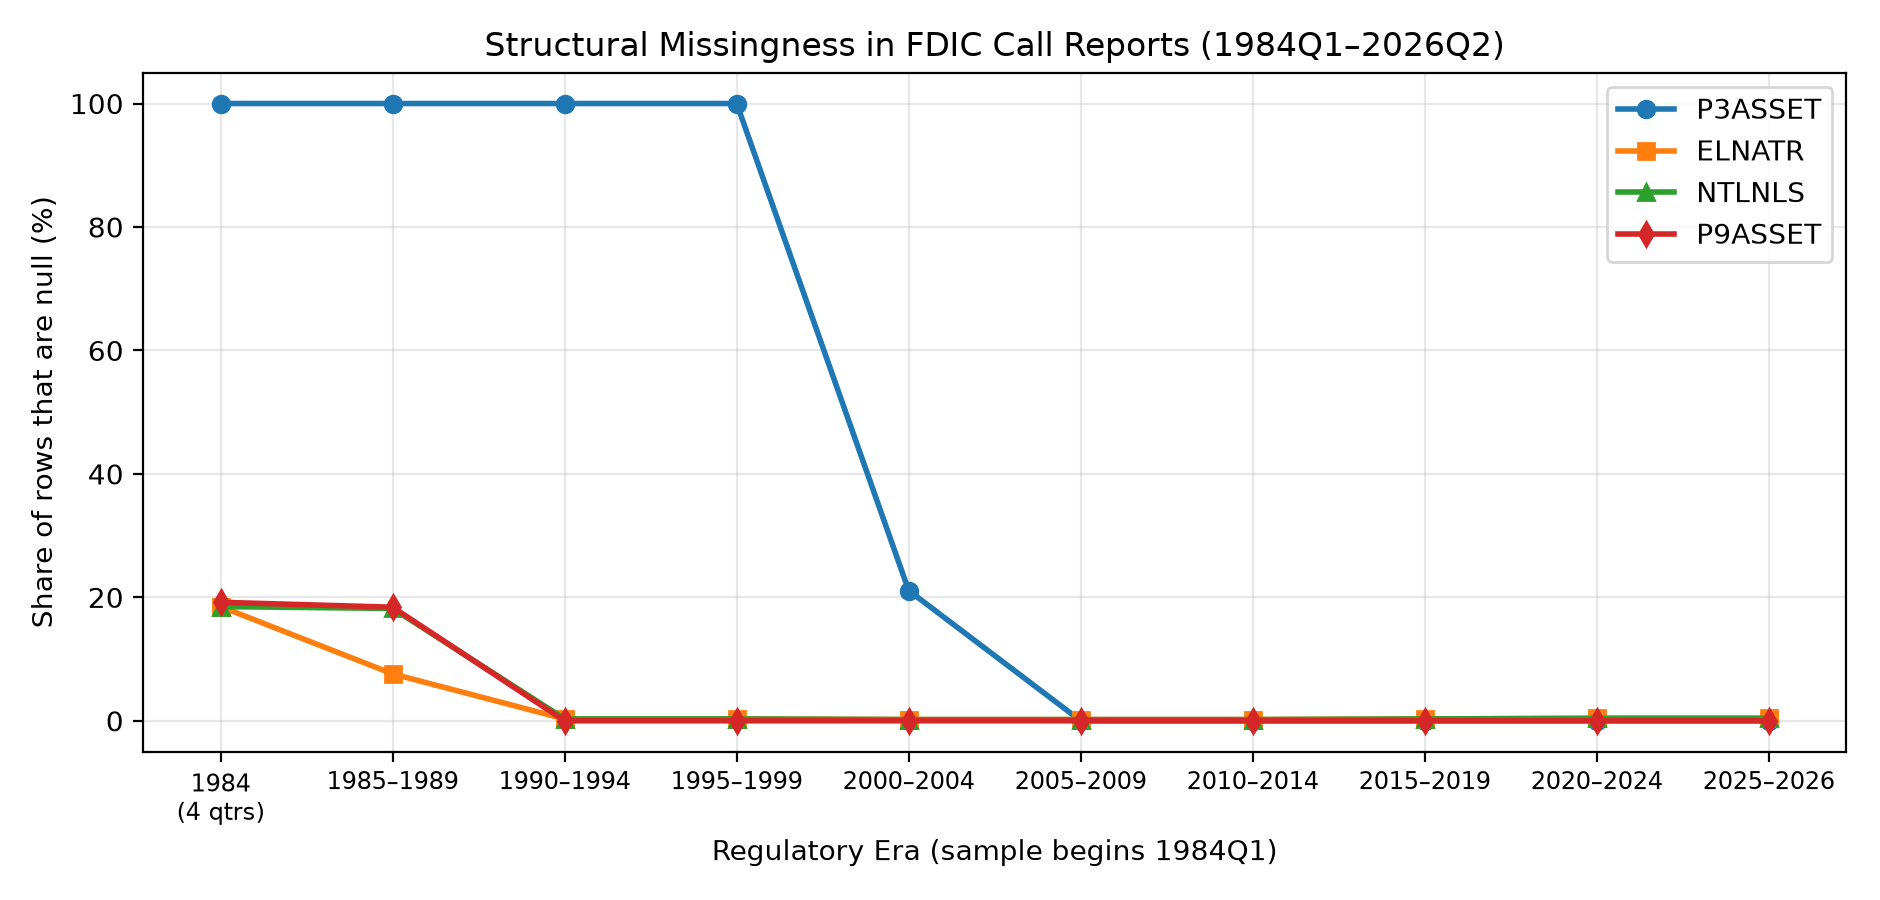

In [3]:
import sys, datetime
from pathlib import Path
from IPython.display import Image, display
sys.path.insert(0, str(Path.cwd().parent))
from src.bfews.panel import decumulate_ytd_flows

# Live unit verification of guarded YTD flow de-cumulation across a missing Q2 gap
toy = pl.DataFrame({
    'CERT': [1, 1, 1], 'REPDTE': [datetime.date(2022, 3, 31), datetime.date(2022, 9, 30), datetime.date(2022, 12, 31)],
    'NETINC': [100.0, 350.0, 500.0], 'INTINC': [50.0, 170.0, 240.0], 'EINTEXP': [10.0, 35.0, 50.0],
    'NONII': [5.0, 15.0, 22.0], 'NONIX': [20.0, 65.0, 90.0], 'ELNATR': [4.0, 12.0, 18.0], 'NTLNLS': [2.0, 7.0, 11.0],
})
dec = decumulate_ytd_flows(toy).select(['REPDTE', 'NETINC', 'NETINC_Q'])
print('Guarded de-cumulation (Q3 after missing Q2 stays null; Q4 = 500 - 350 = 150):')
print(dec)
assert dec['NETINC_Q'].to_list() == [100.0, None, 150.0]
display(Image(filename='../outputs/figures/missingness_by_era.png'))